# EDA: Default of Credit Card Clients (UCI)

Разведочный анализ датасета для PD-модели: структура данных, баланс классов, распределения ключевых признаков, корреляции и первичные выводы для feature engineering.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.data.prepare import clean_data, load_data
from src import config

sns.set_theme(style='whitegrid')
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

raw = load_data()
df = clean_data(raw)
df.head()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,20000.0,2,2,1,24,2,2,-1,-1,-2,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,120000.0,2,2,2,26,-1,2,0,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,90000.0,2,2,2,34,0,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,50000.0,2,2,1,37,0,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,50000.0,1,2,1,57,-1,0,-1,0,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


## 1. Структура данных

In [2]:
print(f'Строк: {df.shape[0]}, колонок: {df.shape[1]}')
print(f'Пропусков: {int(df.isna().sum().sum())}')
df.describe().T

Строк: 30000, колонок: 24
Пропусков: 0


,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.842267,0.744494,1.0,1.00,2.0,2.00,4.0
MARRIAGE,30000.0,1.557267,0.521405,1.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0
PAY_5,30000.0,-0.266200,1.133187,-2.0,-1.00,0.0,0.00,8.0


## 2. Баланс классов

Целевая переменная: дефолт в следующем месяце.

Доля дефолтов: 22.12%


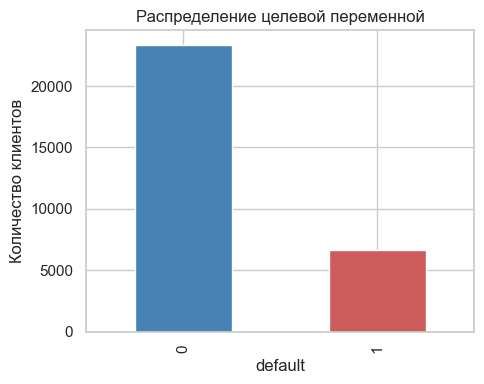

In [3]:
share = df[config.TARGET].mean()
print(f'Доля дефолтов: {share:.2%}')

fig, ax = plt.subplots(figsize=(5, 4))
df[config.TARGET].value_counts().plot.bar(ax=ax, color=['steelblue', 'indianred'])
ax.set_title('Распределение целевой переменной')
ax.set_xlabel('default'); ax.set_ylabel('Количество клиентов')
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / 'target_balance.png', dpi=120)
plt.show()

## 3. Демография и лимит

Распределения возраста и кредитного лимита в разрезе дефолта.

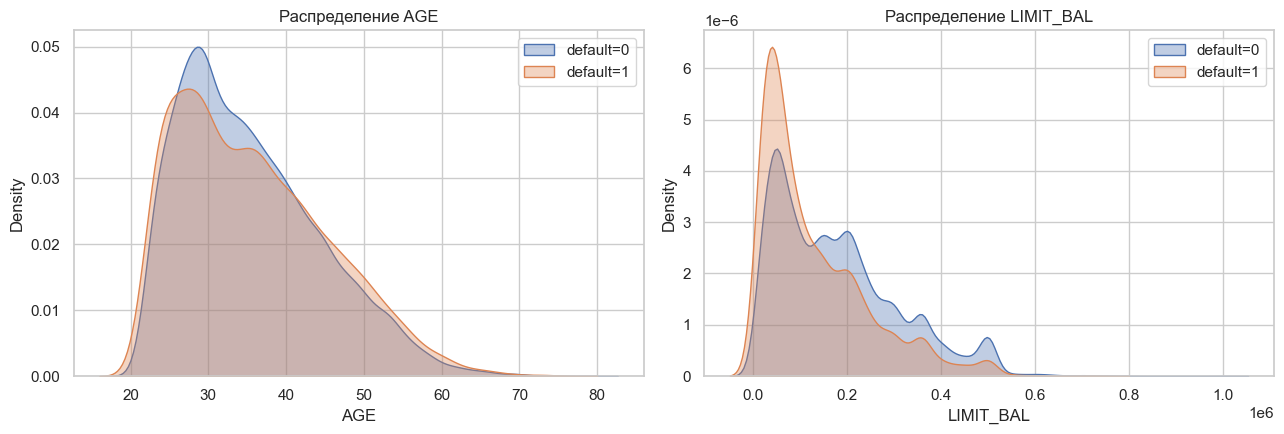

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col in zip(axes, ['AGE', 'LIMIT_BAL']):
    for label, grp in df.groupby(config.TARGET):
        sns.kdeplot(grp[col], ax=ax, label=f'default={label}', fill=True, alpha=0.35)
    ax.set_title(f'Распределение {col}')
    ax.legend()
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / 'demographics.png', dpi=120)
plt.show()

## 4. История платежей

Статус погашения (PAY_0 — самый свежий месяц): значения > 0 — просрочка. Это самый сильный блок предикторов.

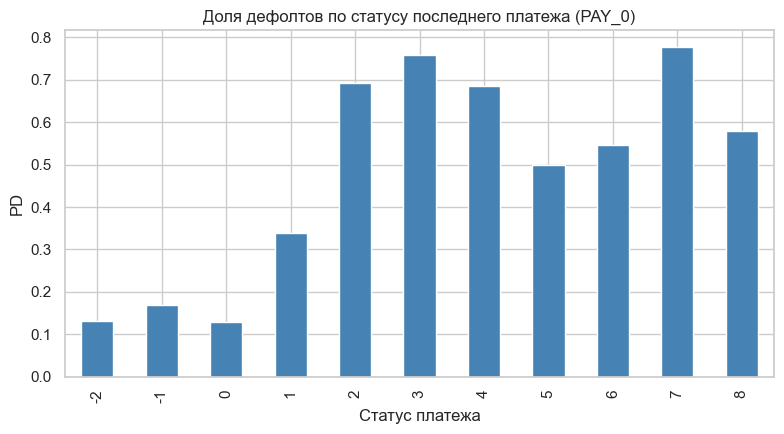

In [5]:
pay_cols = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
default_rate = df.groupby('PAY_0')[config.TARGET].mean()

fig, ax = plt.subplots(figsize=(8, 4.5))
default_rate.plot.bar(ax=ax, color='steelblue')
ax.set_title('Доля дефолтов по статусу последнего платежа (PAY_0)')
ax.set_ylabel('PD'); ax.set_xlabel('Статус платежа')
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / 'pay_status_pd.png', dpi=120)
plt.show()

## 5. Корреляции с целевой переменной

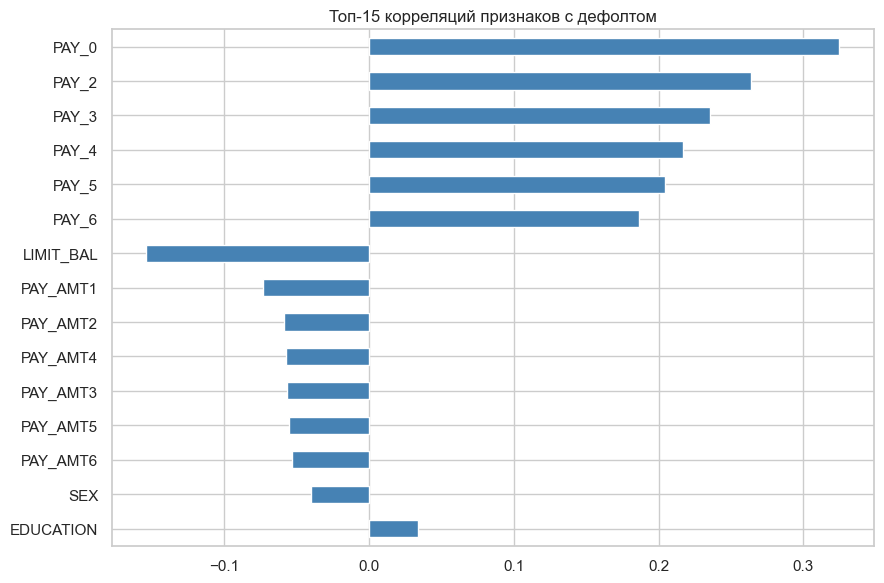

In [6]:
corr = df.corr(numeric_only=True)[config.TARGET].drop(config.TARGET)
corr = corr.reindex(corr.abs().sort_values(ascending=False).index)

fig, ax = plt.subplots(figsize=(9, 6))
corr.head(15).plot.barh(ax=ax, color='steelblue')
ax.set_title('Топ-15 корреляций признаков с дефолтом')
ax.invert_yaxis()
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / 'correlations.png', dpi=120)
plt.show()

## Выводы

1. Классы несбалансированы (~22% дефолтов) — фокус на ROC-AUC и PR-метриках, есть смысл пробовать class_weight='balanced'.
2. Статусы просрочек (PAY_0..PAY_6) — ключевые предикторы: PD монотонно растёт с глубиной просрочки.
3. На их основе построены агрегированные признаки: средняя/максимальная просрочка, число месяцев с просрочкой, утилизация лимита, доля погашения.
4. Пропусков в данных нет; аномальные категории EDUCATION (0,5,6) и MARRIAGE (0) приведены к «другое» на этапе очистки.